In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import soundfile as sf
import numpy as np
import librosa

In [2]:
import os
from pathlib import Path

root_dir = Path.cwd().parent

print(root_dir)

print("--- Contents of project root directory ---")
print(os.listdir(root_dir))
DATASET_DIR = Path.cwd().parent / "ESC-50-master"
AUDIO_DIR = DATASET_DIR / "audio"
METADATA_FILE = DATASET_DIR / "meta" / "esc50.csv"


print("Dataset root exists:", DATASET_DIR.exists())
print("Audio folder exists:", AUDIO_DIR)
print("Metadata exists:", METADATA_FILE.exists())

c:\Users\MinhalHnaqvi\Desktop\DL-ESC50
--- Contents of project root directory ---
['.git', '.gitignore', '.venv', 'ESC-50-master', 'ESC-50.zip', 'notebook', 'README.md', 'requirements.txt']
Dataset root exists: True
Audio folder exists: c:\Users\MinhalHnaqvi\Desktop\DL-ESC50\ESC-50-master\audio
Metadata exists: True


In [3]:
df = pd.read_csv(METADATA_FILE)

print("Total samples:", len(df))
print("Total classes:", df["category"].nunique())
print("\nColumns:")
print(df.columns.tolist())

display(df.head())

Total samples: 2000
Total classes: 50

Columns:
['filename', 'fold', 'target', 'category', 'esc10', 'src_file', 'take']


,filename,fold,target,category,esc10,src_file,take
0,1-100032-A-0.wav,1,0,dog,True,100032,A
1,1-100038-A-14.wav,1,14,chirping_birds,False,100038,A
2,1-100210-A-36.wav,1,36,vacuum_cleaner,False,100210,A
3,1-100210-B-36.wav,1,36,vacuum_cleaner,False,100210,B
4,1-101296-A-19.wav,1,19,thunderstorm,False,101296,A


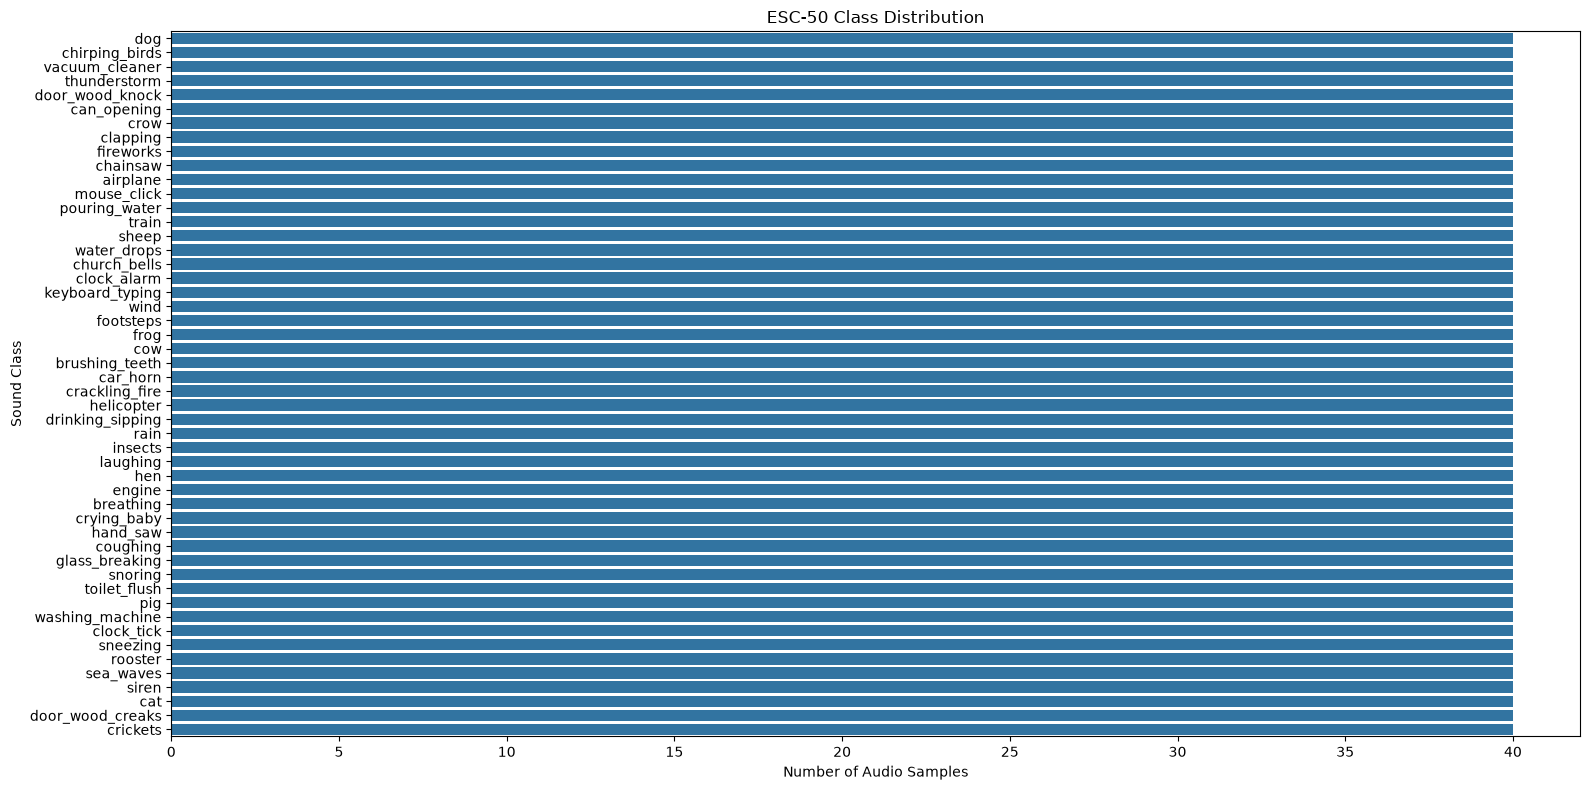

In [4]:
plt.figure(figsize=(16, 8))

sns.countplot(
    data=df,
    y="category",
    order=df["category"].value_counts().index
)

plt.title("ESC-50 Class Distribution")
plt.xlabel("Number of Audio Samples")
plt.ylabel("Sound Class")
plt.tight_layout()
plt.show()

In [5]:
print(df.groupby("fold").size().sort_index())

train_df = df[df["fold"].isin([1, 2, 3])].copy()
val_df = df[df["fold"] == 4].copy()
test_df = df[df["fold"] == 5].copy()

print("\nTraining samples:", len(train_df))
print("Validation samples:", len(val_df))
print("Test samples:", len(test_df))

fold
1    400
2    400
3    400
4    400
5    400
dtype: int64

Training samples: 1200
Validation samples: 400
Test samples: 400


filename    1-100032-A-0.wav
fold                       1
target                     0
category                 dog
esc10                   True
src_file              100032
take                       A
Name: 0, dtype: object
c:\Users\MinhalHnaqvi\Desktop\DL-ESC50\ESC-50-master\audio\1-100032-A-0.wav
Filename: 1-100032-A-0.wav
Category: dog
Sample rate: 44100
Duration: 5.0 seconds


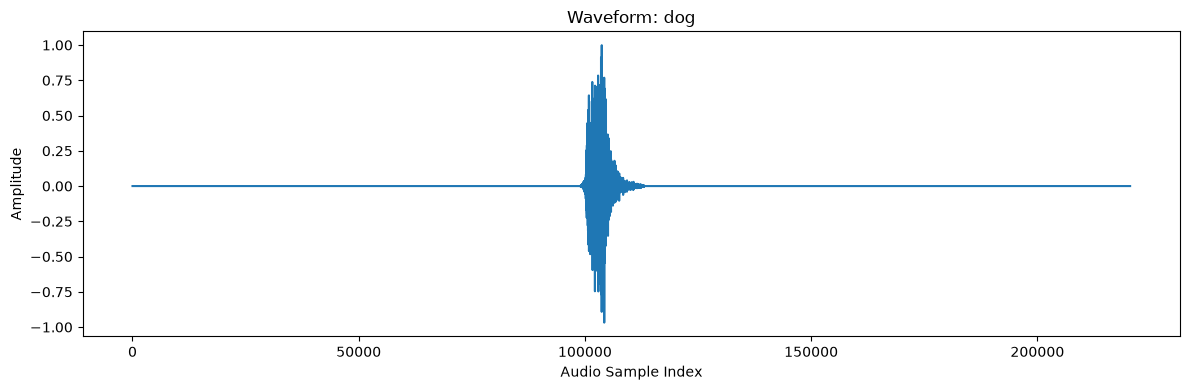

In [6]:
sample = df.iloc[0]
audio_path = AUDIO_DIR / sample["filename"]

print(sample)
print(audio_path)

audio, sample_rate = sf.read(audio_path)

print("Filename:", sample["filename"])
print("Category:", sample["category"])
print("Sample rate:", sample_rate)
print("Duration:", len(audio) / sample_rate, "seconds")

plt.figure(figsize=(12, 4))
plt.plot(range(len(audio)), audio)
plt.title(f"Waveform: {sample['category']}")
plt.xlabel("Audio Sample Index")
plt.ylabel("Amplitude")
plt.tight_layout()
plt.show()

In [7]:
def generateAudioRelativePath(fileName):
    return AUDIO_DIR / fileName

In [8]:
df["relative_path"] = df["filename"].apply(generateAudioRelativePath)

In [9]:
df.head()

,filename,fold,target,category,esc10,src_file,take,relative_path
0,1-100032-A-0.wav,1,0,dog,True,100032,A,c:\Users\MinhalHnaqvi\Desktop\DL-ESC50\ESC-50-...
1,1-100038-A-14.wav,1,14,chirping_birds,False,100038,A,c:\Users\MinhalHnaqvi\Desktop\DL-ESC50\ESC-50-...
2,1-100210-A-36.wav,1,36,vacuum_cleaner,False,100210,A,c:\Users\MinhalHnaqvi\Desktop\DL-ESC50\ESC-50-...
3,1-100210-B-36.wav,1,36,vacuum_cleaner,False,100210,B,c:\Users\MinhalHnaqvi\Desktop\DL-ESC50\ESC-50-...
4,1-101296-A-19.wav,1,19,thunderstorm,False,101296,A,c:\Users\MinhalHnaqvi\Desktop\DL-ESC50\ESC-50-...


In [10]:
def getAudioDurations(filepath):
    return librosa.get_duration(path=filepath)

In [11]:
df["duration"] = df["relative_path"].apply(getAudioDurations)

c:\Users\MinhalHnaqvi\Desktop\DL-ESC50\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [13]:
display(df.head())
print("Verifing Durations varients:", df.duration.nunique())

,filename,fold,target,category,esc10,src_file,take,relative_path,duration
0,1-100032-A-0.wav,1,0,dog,True,100032,A,c:\Users\MinhalHnaqvi\Desktop\DL-ESC50\ESC-50-...,5.0
1,1-100038-A-14.wav,1,14,chirping_birds,False,100038,A,c:\Users\MinhalHnaqvi\Desktop\DL-ESC50\ESC-50-...,5.0
2,1-100210-A-36.wav,1,36,vacuum_cleaner,False,100210,A,c:\Users\MinhalHnaqvi\Desktop\DL-ESC50\ESC-50-...,5.0
3,1-100210-B-36.wav,1,36,vacuum_cleaner,False,100210,B,c:\Users\MinhalHnaqvi\Desktop\DL-ESC50\ESC-50-...,5.0
4,1-101296-A-19.wav,1,19,thunderstorm,False,101296,A,c:\Users\MinhalHnaqvi\Desktop\DL-ESC50\ESC-50-...,5.0


Verifing Durations varients: 1


In [14]:
sample = df.iloc[0]

audio_path = AUDIO_DIR / sample["filename"]

audio, sr = librosa.load(
    audio_path,
    sr=22050,
    mono=True
)

print("Filename:", sample["filename"])
print("Category:", sample["category"])
print("Sample rate:", sr)
print("Audio duration in Sec:", sample["duration"])
print("Audio shape:", audio.shape)

Filename: 1-100032-A-0.wav
Category: dog
Sample rate: 22050
Audio duration in Sec: 5.0
Audio shape: (110250,)


In [15]:
mel_spectrogram = librosa.feature.melspectrogram(
    y=audio,
    sr=sr,
    n_fft=1024,
    hop_length=512,
    n_mels=128,
    power=2.0
)

log_mel_spectrogram = librosa.power_to_db(
    mel_spectrogram,
    ref=np.max
)

print("Mel spectrogram shape:", mel_spectrogram.shape)
print("Log-Mel spectrogram shape:", log_mel_spectrogram.shape)

Mel spectrogram shape: (128, 216)
Log-Mel spectrogram shape: (128, 216)


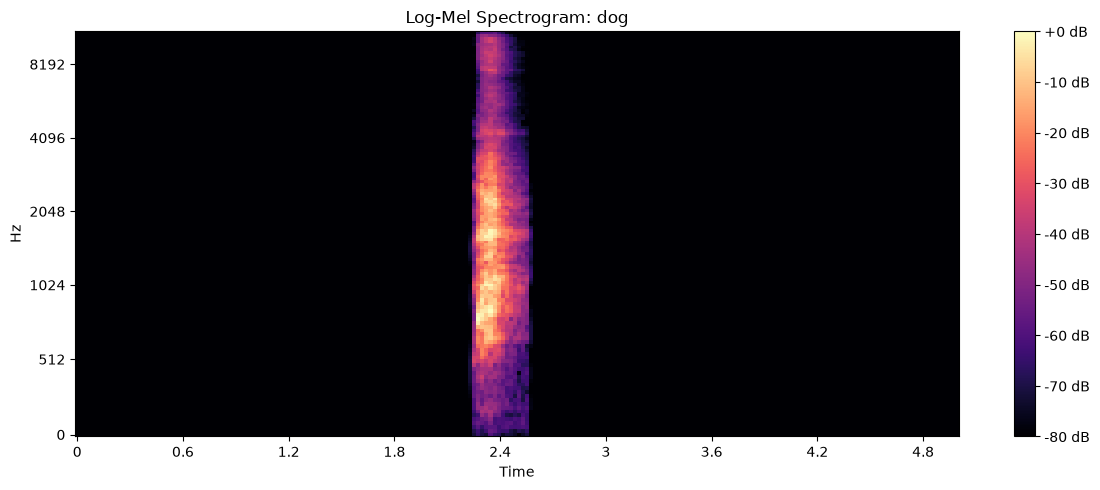

In [16]:
plt.figure(figsize=(12, 5))

librosa.display.specshow(
    log_mel_spectrogram,
    sr=sr,
    hop_length=512,
    x_axis="time",
    y_axis="mel"
)

plt.colorbar(format="%+2.0f dB")
plt.title(f"Log-Mel Spectrogram: {sample['category']}")
plt.tight_layout()
plt.show()

In [17]:
print("Category:", sample["category"])
print("Audio duration:", round(len(audio) / sr, 2), "seconds")
print("Sample rate:", sr)

print("Mel spectrogram shape:", mel_spectrogram.shape)
print("Log-Mel spectrogram shape:", log_mel_spectrogram.shape)

print("Contains NaN:", np.isnan(log_mel_spectrogram).any())
print("Contains infinity:", np.isinf(log_mel_spectrogram).any())
print("Minimum dB:", log_mel_spectrogram.min())
print("Maximum dB:", log_mel_spectrogram.max())

Category: dog
Audio duration: 5.0 seconds
Sample rate: 22050
Mel spectrogram shape: (128, 216)
Log-Mel spectrogram shape: (128, 216)
Contains NaN: False
Contains infinity: False
Minimum dB: -80.0
Maximum dB: 0.0


In [18]:
SAMPLE_RATE = 22050
DURATION = 5
N_MELS = 128
N_FFT = 1024
HOP_LENGTH = 512
EXPECTED_SAMPLES = SAMPLE_RATE * DURATION

In [19]:
features = []
labels = []
folds = []
filenames = []

In [20]:
from tqdm.auto import tqdm

for index, row in tqdm(df.iterrows(), total=len(df), desc="Processing audio"):
    audio_path = AUDIO_DIR / row["filename"]

    audio, sr = librosa.load(audio_path, sr=SAMPLE_RATE, mono=True)

    if len(audio) < EXPECTED_SAMPLES: 
        audio = np.pad(audio, (0, EXPECTED_SAMPLES - len(audio)))
    else:
        audio = audio[:EXPECTED_SAMPLES]

    mel = librosa.feature.melspectrogram( y=audio, sr=SAMPLE_RATE, n_fft=N_FFT, hop_length=HOP_LENGTH, n_mels=N_MELS, power=2.0 )
    log_mel = librosa.power_to_db(mel, ref=np.max)

    features.append(log_mel)
    labels.append(row["category"])
    folds.append(row["fold"])
    filenames.append(row["filename"])

Processing audio: 100%|██████████| 2000/2000 [00:16<00:00, 123.73it/s]


In [21]:
display(features)

[array([[-80., -80., -80., ..., -80., -80., -80.],
        [-80., -80., -80., ..., -80., -80., -80.],
        [-80., -80., -80., ..., -80., -80., -80.],
        ...,
        [-80., -80., -80., ..., -80., -80., -80.],
        [-80., -80., -80., ..., -80., -80., -80.],
        [-80., -80., -80., ..., -80., -80., -80.]],
       shape=(128, 216), dtype=float32),
 array([[-69.29114 , -75.13856 , -80.      , ..., -75.43763 , -80.      ,
         -55.852463],
        [-67.81628 , -72.63211 , -80.      , ..., -77.23958 , -76.12548 ,
         -56.639893],
        [-67.553375, -74.11048 , -80.      , ..., -80.      , -77.00659 ,
         -55.751125],
        ...,
        [-51.990425, -30.8449  , -30.723265, ..., -63.701332, -62.808563,
         -60.178024],
        [-57.681553, -36.26712 , -37.218422, ..., -66.83263 , -64.93084 ,
         -64.5773  ],
        [-64.42753 , -78.86896 , -80.      , ..., -77.32137 , -79.05121 ,
         -73.04074 ]], shape=(128, 216), dtype=float32),
 array([[-28.66

In [22]:
X = np.array(features, dtype=np.float32)
y = np.array(labels)
folds = np.array(folds)
filenames = np.array(filenames)

print("\nFeature extraction complete!")
print("Features shape:", X.shape)
print("Labels shape:", y.shape)
print("Folds shape:", folds.shape)
print("Unique classes:", len(np.unique(y)))
print("Contains NaN:", np.isnan(X).any())
print("Contains infinity:", np.isinf(X).any())


Feature extraction complete!
Features shape: (2000, 128, 216)
Labels shape: (2000,)
Folds shape: (2000,)
Unique classes: 50
Contains NaN: False
Contains infinity: False


In [23]:
display(df.fold.nunique())
display(df.fold.unique())

5

array([1, 2, 3, 4, 5])

In [24]:
# Step 1: Select recordings using the official ESC-50 folds
train_mask = np.isin(folds, [1, 2, 3])
val_mask = folds == 4
test_mask = folds == 5

# Step 2: Split features and labels
X_train, y_train = X[train_mask], y[train_mask]
X_val, y_val = X[val_mask], y[val_mask]
X_test, y_test = X[test_mask], y[test_mask]

# Step 3: Check the split
print("Training samples:", len(X_train))
print("Validation samples:", len(X_val))
print("Test samples:", len(X_test))

print("\nClasses in training:", len(np.unique(y_train)))
print("Classes in validation:", len(np.unique(y_val)))
print("Classes in test:", len(np.unique(y_test)))

print("\nTraining folds:", np.unique(folds[train_mask]))
print("Validation folds:", np.unique(folds[val_mask]))
print("Test folds:", np.unique(folds[test_mask]))

Training samples: 1200
Validation samples: 400
Test samples: 400

Classes in training: 50
Classes in validation: 50
Classes in test: 50

Training folds: [1 2 3]
Validation folds: [4]
Test folds: [5]


In [25]:
from sklearn.preprocessing import LabelEncoder

label_encoder = LabelEncoder()

y_train_encoded = label_encoder.fit_transform(y_train)
y_val_encoded = label_encoder.transform(y_val)
y_test_encoded = label_encoder.transform(y_test)

print("Number of classes:", len(label_encoder.classes_))
print("First 10 class names:", label_encoder.classes_[:10])
print("First 10 encoded labels:", y_train_encoded[:10])

Number of classes: 50
First 10 class names: ['airplane' 'breathing' 'brushing_teeth' 'can_opening' 'car_horn' 'cat'
 'chainsaw' 'chirping_birds' 'church_bells' 'clapping']
First 10 encoded labels: [18  7 46 46 43 43 20  3 16 20]


In [26]:
X_train_cnn = X_train[..., np.newaxis]
X_val_cnn = X_val[..., np.newaxis]
X_test_cnn = X_test[..., np.newaxis]

print("Training shape:", X_train_cnn.shape)
print("Validation shape:", X_val_cnn.shape)
print("Test shape:", X_test_cnn.shape)

Training shape: (1200, 128, 216, 1)
Validation shape: (400, 128, 216, 1)
Test shape: (400, 128, 216, 1)


In [27]:
# Calculate normalization statistics from training data only
feature_mean = X_train_cnn.mean()
feature_std = X_train_cnn.std()

# Apply the same normalization to all datasets
X_train_norm = (X_train_cnn - feature_mean) / (feature_std + 1e-8)
X_val_norm = (X_val_cnn - feature_mean) / (feature_std + 1e-8)
X_test_norm = (X_test_cnn - feature_mean) / (feature_std + 1e-8)

print("Training:", X_train_norm.shape)
print("Validation:", X_val_norm.shape)
print("Test:", X_test_norm.shape)

Training: (1200, 128, 216, 1)
Validation: (400, 128, 216, 1)
Test: (400, 128, 216, 1)


In [29]:
# %pip install --upgrade setuptools tensorflow

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

# Make experiments reproducible
SEED = 42
tf.keras.utils.set_random_seed(SEED)


A module that was compiled using NumPy 1.x cannot be run in
NumPy 2.5.2 as it may crash. To support both 1.x and 2.x
versions of NumPy, modules must be compiled with NumPy 2.0.
Some module may need to rebuild instead e.g. with 'pybind11>=2.12'.

If you are a user of the module, the easiest solution will be to
downgrade to 'numpy<2' or try to upgrade the affected module.
We expect that some modules will need time to support NumPy 2.

Traceback (most recent call last):  File "<frozen runpy>", line 198, in _run_module_as_main
  File "<frozen runpy>", line 88, in _run_code
  File "c:\Users\MinhalHnaqvi\Desktop\DL-ESC50\.venv\Lib\site-packages\ipykernel_launcher.py", line 18, in <module>
    app.launch_new_instance()
  File "c:\Users\MinhalHnaqvi\Desktop\DL-ESC50\.venv\Lib\site-packages\traitlets\config\application.py", line 1080, in launch_instance
    app.start()
  File "c:\Users\MinhalHnaqvi\Desktop\DL-ESC50\.venv\Lib\site-packages\ipykernel\kernelapp.py", line 768, in start
    self.io

ImportError: 
A module that was compiled using NumPy 1.x cannot be run in
NumPy 2.5.2 as it may crash. To support both 1.x and 2.x
versions of NumPy, modules must be compiled with NumPy 2.0.
Some module may need to rebuild instead e.g. with 'pybind11>=2.12'.

If you are a user of the module, the easiest solution will be to
downgrade to 'numpy<2' or try to upgrade the affected module.
We expect that some modules will need time to support NumPy 2.



ImportError: numpy.core._multiarray_umath failed to import

ImportError: numpy.core.umath failed to import

In [ ]:
model = keras.Sequential([
    keras.Input(shape=(128, 216, 1)),

    layers.Conv2D( 32, kernel_size=3, padding="same", activation="relu" ),
    layers.MaxPooling2D(pool_size=2),

    layers.Conv2D( 64, kernel_size=3, padding="same", activation="relu" ),
    layers.MaxPooling2D(pool_size=2),

    layers.Conv2D( 128, kernel_size=3, padding="same", activation="relu"),
    layers.MaxPooling2D(pool_size=2),

    layers.GlobalAveragePooling2D(),
    layers.Dropout(0.3),
    layers.Dense(50, activation="softmax")
])

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 128, 216, 32)   │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 64, 108, 32)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 64, 108, 64)    │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 32, 54, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 32, 54, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 16, 27, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 50)             │         6,450 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 99,122 (387.20 KB)

 Trainable params: 99,122 (387.20 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("Model compiled successfully!")

Model compiled successfully!


In [ ]:
history = model.fit(
    X_train_norm,
    y_train_encoded,
    validation_data=(X_val_norm, y_val_encoded),
    epochs=20,
    # batch_size=32,
)

Epoch 1/20
38/38 ━━━━━━━━━━━━━━━━━━━━ 12s 268ms/step - accuracy: 0.0258 - loss: 3.8740 - val_accuracy: 0.0550 - val_loss: 3.7492
Epoch 2/20
38/38 ━━━━━━━━━━━━━━━━━━━━ 10s 262ms/step - accuracy: 0.0358 - loss: 3.7286 - val_accuracy: 0.0575 - val_loss: 3.6011
Epoch 3/20
38/38 ━━━━━━━━━━━━━━━━━━━━ 10s 264ms/step - accuracy: 0.0450 - loss: 3.6216 - val_accuracy: 0.0925 - val_loss: 3.4783
Epoch 4/20
38/38 ━━━━━━━━━━━━━━━━━━━━ 10s 266ms/step - accuracy: 0.0575 - loss: 3.5243 - val_accuracy: 0.0850 - val_loss: 3.4034
Epoch 5/20
38/38 ━━━━━━━━━━━━━━━━━━━━ 10s 265ms/step - accuracy: 0.0675 - loss: 3.4465 - val_accuracy: 0.1375 - val_loss: 3.3149
Epoch 6/20
38/38 ━━━━━━━━━━━━━━━━━━━━ 12s 306ms/step - accuracy: 0.1083 - loss: 3.3241 - val_accuracy: 0.1600 - val_loss: 3.1903
Epoch 7/20
38/38 ━━━━━━━━━━━━━━━━━━━━ 10s 266ms/step - accuracy: 0.1150 - loss: 3.2104 - val_accuracy: 0.1825 - val_loss: 3.0524
Epoch 8/20
38/38 ━━━━━━━━━━━━━━━━━━━━ 10s 263ms/step - accuracy: 0.1533 - loss: 3.0961 - val_accu

In [ ]:
print("Training completed!")
print("Final training accuracy:", history.history["accuracy"][-1])
print("Final validation accuracy:", history.history["val_accuracy"][-1])
print("Final training loss:", history.history["loss"][-1])
print("Final validation loss:",history.history["val_loss"][-1])

Training completed!
Final training accuracy: 0.3216666579246521
Final validation accuracy: 0.4074999988079071
Final training loss: 2.304898977279663
Final validation loss: 2.1772804260253906


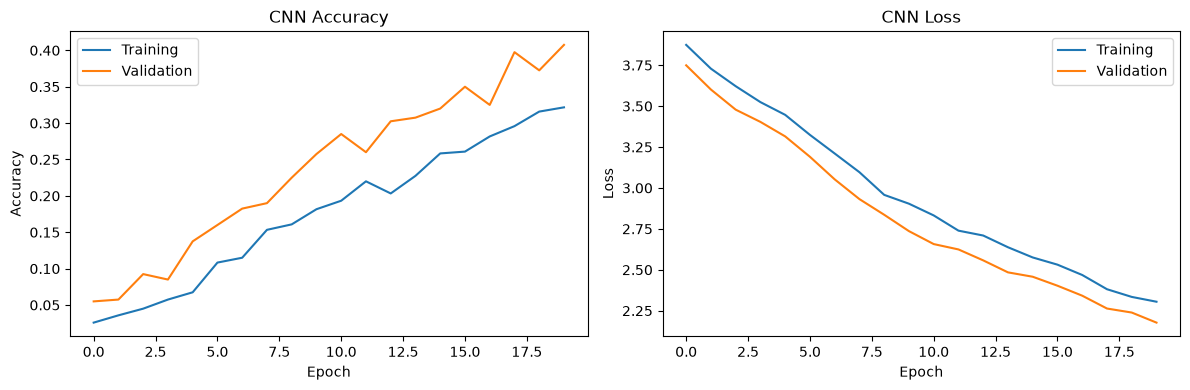

In [ ]:
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="Training")
plt.plot(history.history["val_accuracy"], label="Validation")
plt.title("CNN Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="Training")
plt.plot(history.history["val_loss"], label="Validation")
plt.title("CNN Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.tight_layout()
plt.show()

In [ ]:
best_epoch = ( min( range(len(history.history["val_loss"])), key=lambda i: history.history["val_loss"][i]) + 1 )

print("Epochs trained:", len(history.history["accuracy"]))
print("Best validation-loss epoch:", best_epoch)
print("Best validation loss:", min(history.history["val_loss"]))
print("Best validation accuracy:", max(history.history["val_accuracy"]))

Epochs trained: 20
Best validation-loss epoch: 20
Best validation loss: 2.1772804260253906
Best validation accuracy: 0.4074999988079071


In [ ]:
from tqdm.auto import tqdm

class TqdmProgressBar(tf.keras.callbacks.Callback):
    def on_train_begin(self, logs=None):
        self.epoch_bar = tqdm(
            total=self.params["epochs"],
            desc="Training CNN",
            unit="epoch"
        )

    def on_epoch_begin(self, epoch, logs=None):
        self.batch_bar = tqdm(
            total=self.params.get("steps", 1),
            desc=f"Epoch {epoch + 1}",
            unit="batch",
            leave=False
        )

    def on_train_batch_end(self, batch, logs=None):
        logs = logs or {}
        self.batch_bar.update(1)
        self.batch_bar.set_postfix(
            loss=f"{logs.get('loss', 0):.4f}",
            accuracy=f"{logs.get('accuracy', 0):.4f}"
        )

    def on_epoch_end(self, epoch, logs=None):
        logs = logs or {}
        self.batch_bar.close()
        self.epoch_bar.update(1)
        self.epoch_bar.set_postfix(
            loss=f"{logs.get('loss', 0):.4f}",
            val_loss=f"{logs.get('val_loss', 0):.4f}",
            accuracy=f"{logs.get('accuracy', 0):.4f}",
            val_acc=f"{logs.get('val_accuracy', 0):.4f}"
        )

    def on_train_end(self, logs=None):
        self.epoch_bar.close()

In [ ]:
early_stopping = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=6,
    restore_best_weights=True,
    verbose=1
)

lr_scheduler = keras.callbacks.ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=2,
    min_lr=1e-6,
    verbose=1
)

history_long = model.fit(
    X_train_norm,
    y_train_encoded,
    validation_data=(X_val_norm, y_val_encoded),
    epochs=40,
    batch_size=32,
    callbacks=[ lr_scheduler, early_stopping ]
)

Epoch 1/40
38/38 ━━━━━━━━━━━━━━━━━━━━ 10s 266ms/step - accuracy: 0.3383 - loss: 2.2987 - val_accuracy: 0.4425 - val_loss: 2.1467 - learning_rate: 0.0010
Epoch 2/40
38/38 ━━━━━━━━━━━━━━━━━━━━ 10s 268ms/step - accuracy: 0.3475 - loss: 2.2421 - val_accuracy: 0.4825 - val_loss: 2.0948 - learning_rate: 0.0010
Epoch 3/40
38/38 ━━━━━━━━━━━━━━━━━━━━ 10s 268ms/step - accuracy: 0.3267 - loss: 2.1936 - val_accuracy: 0.4700 - val_loss: 2.0578 - learning_rate: 0.0010
Epoch 4/40
38/38 ━━━━━━━━━━━━━━━━━━━━ 10s 266ms/step - accuracy: 0.3883 - loss: 2.1209 - val_accuracy: 0.4475 - val_loss: 2.0223 - learning_rate: 0.0010
Epoch 5/40
38/38 ━━━━━━━━━━━━━━━━━━━━ 10s 269ms/step - accuracy: 0.4008 - loss: 2.0277 - val_accuracy: 0.4850 - val_loss: 1.9732 - learning_rate: 0.0010
Epoch 6/40
38/38 ━━━━━━━━━━━━━━━━━━━━ 10s 264ms/step - accuracy: 0.3917 - loss: 2.0419 - val_accuracy: 0.4600 - val_loss: 1.9476 - learning_rate: 0.0010
Epoch 7/40
38/38 ━━━━━━━━━━━━━━━━━━━━ 10s 267ms/step - accuracy: 0.4158 - loss: 1.

In [ ]:
print("Epochs completed:", len(history_long.history["accuracy"]))
print("Best validation accuracy:", max(history_long.history["val_accuracy"]))
print("Best validation loss:", min(history_long.history["val_loss"]))
print("Final training accuracy:", history_long.history["accuracy"][-1])

Epochs completed: 40
Best validation accuracy: 0.6474999785423279
Best validation loss: 1.3251700401306152
Final training accuracy: 0.6433333158493042


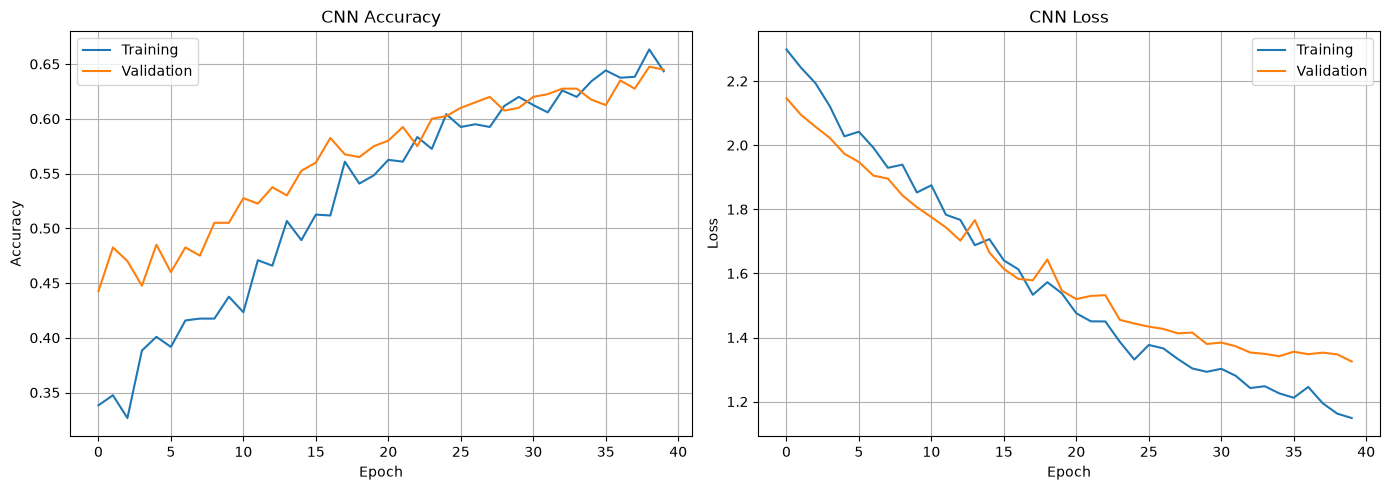

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Accuracy
axes[0].plot(history_long.history["accuracy"], label="Training")
axes[0].plot(history_long.history["val_accuracy"], label="Validation")
axes[0].set_title("CNN Accuracy")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Accuracy")
axes[0].legend()
axes[0].grid(True)

# Loss
axes[1].plot(history_long.history["loss"], label="Training")
axes[1].plot(history_long.history["val_loss"], label="Validation")
axes[1].set_title("CNN Loss")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Loss")
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.show()

In [ ]:
best_epoch = ( min( range(len(history_long.history["val_loss"])), key=lambda i: history_long.history["val_loss"][i] ) + 1 )

print("Best epoch in this run:", best_epoch)
print("Best validation loss:", min(history_long.history["val_loss"]))
print("Validation accuracy at best-loss epoch:", history_long.history["val_accuracy"][best_epoch - 1])

Best epoch in this run: 40
Best validation loss: 1.3251700401306152
Validation accuracy at best-loss epoch: 0.6449999809265137


In [ ]:
from pathlib import Path
import json

OUTPUT_DIR = Path("outputs")
OUTPUT_DIR.mkdir(exist_ok=True)

# Save the trained baseline model
model.save(OUTPUT_DIR / "cnn_baseline.keras")

# Save the training history for later comparison
with open(OUTPUT_DIR / "cnn_baseline_history.json", "w") as f:
    json.dump(
        {
            key: [float(value) for value in values]
            for key, values in history_long.history.items()
        },
        f,
        indent=2
    )

print("Baseline model and training history saved.")

Baseline model and training history saved.


In [ ]:
SAMPLE_RATE = 22050
N_MFCC = 40

mfcc_features = []

for filename in tqdm(filenames, desc="Extracting MFCC features"):
    audio_path = AUDIO_DIR / filename

    audio, sr = librosa.load(
        audio_path,
        sr=SAMPLE_RATE,
        mono=True,
        duration=5
    )

    # Extract 40 MFCC coefficients from the audio
    mfcc = librosa.feature.mfcc(
        y=audio,
        sr=sr,
        n_mfcc=N_MFCC,
        n_fft=1024,
        hop_length=512
    )

    # Average each coefficient across time
    mfcc_summary = np.mean(mfcc, axis=1)
    mfcc_features.append(mfcc_summary)

X_mfcc = np.asarray(mfcc_features, dtype=np.float32)

print("MFCC feature shape:", X_mfcc.shape)
print("Expected samples:", len(y))
print("Contains NaN:", np.isnan(X_mfcc).any())


Extracting MFCC features: 100%|██████████| 2000/2000 [00:15<00:00, 131.59it/s]

MFCC feature shape: (2000, 40)
Expected samples: 2000
Contains NaN: False


In [ ]:

from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, classification_report

# Use the same official ESC-50 folds as the CNN
X_mfcc_train = X_mfcc[train_mask]
X_mfcc_val = X_mfcc[val_mask]

# Standardize using training data only
scaler = StandardScaler()
X_mfcc_train_scaled = scaler.fit_transform(X_mfcc_train)
X_mfcc_val_scaled = scaler.transform(X_mfcc_val)

# Train the SVM
svm_model = SVC(kernel="rbf", C=10, gamma="scale")
svm_model.fit(X_mfcc_train_scaled, y_train_encoded)

# Evaluate on validation data
svm_predictions = svm_model.predict(X_mfcc_val_scaled)
svm_val_accuracy = accuracy_score( y_val_encoded, svm_predictions )

print(f"SVM validation accuracy: {svm_val_accuracy:.2%}")
print("\nClassification report:")
print( classification_report( y_val_encoded, svm_predictions, labels=np.arange(len(label_encoder.classes_)), target_names=label_encoder.classes_, zero_division=0) )

SVM validation accuracy: 35.25%

Classification report:
                  precision    recall  f1-score   support

        airplane       0.30      0.38      0.33         8
       breathing       0.00      0.00      0.00         8
  brushing_teeth       0.60      0.75      0.67         8
     can_opening       0.62      0.62      0.62         8
        car_horn       0.27      0.50      0.35         8
             cat       0.00      0.00      0.00         8
        chainsaw       0.50      0.62      0.56         8
  chirping_birds       0.40      0.25      0.31         8
    church_bells       0.23      0.88      0.36         8
        clapping       0.44      1.00      0.62         8
     clock_alarm       0.67      0.50      0.57         8
      clock_tick       0.25      0.25      0.25         8
        coughing       0.50      0.25      0.33         8
             cow       0.50      0.38      0.43         8
  crackling_fire       1.00      0.38      0.55         8
        cricket

In [ ]:
comparison = pd.DataFrame({
    "Model": [ "CNN (Log-Mel Spectrograms)", "SVM (MFCC Features)" ],
    "Validation Accuracy": [ max(history_long.history["val_accuracy"]), svm_val_accuracy ]
})

comparison["Validation Accuracy (%)"] = ( comparison["Validation Accuracy"] * 100 ).round(2)
comparison = comparison.drop(columns=["Validation Accuracy"])

display(comparison)


,Model,Validation Accuracy (%)
0,CNN (Log-Mel Spectrograms),64.75
1,SVM (MFCC Features),35.25


In [ ]:
model_lr = keras.Sequential([
    keras.Input(shape=(128, 216, 1)),

    layers.Conv2D(32, 3, padding="same", activation="relu"),
    layers.MaxPooling2D(2),

    layers.Conv2D(64, 3, padding="same", activation="relu"),
    layers.MaxPooling2D(2),

    layers.Conv2D(128, 3, padding="same", activation="relu"),
    layers.MaxPooling2D(2),

    layers.GlobalAveragePooling2D(),
    layers.Dropout(0.3),
    layers.Dense(50, activation="softmax")
])

model_lr.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("Fresh CNN created.")
print("Initial learning rate:",
      float(model_lr.optimizer.learning_rate.numpy()))


Fresh CNN created.
Initial learning rate: 0.0010000000474974513


In [ ]:

lr_scheduler = keras.callbacks.ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=3,
    min_lr=1e-6,
    verbose=1
)

early_stopping_lr = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=8,
    restore_best_weights=True,
    verbose=1
)

history_lr = model_lr.fit(
    X_train_norm,
    y_train_encoded,
    validation_data=(X_val_norm, y_val_encoded),
    epochs=40,
    batch_size=32,
    callbacks=[lr_scheduler, early_stopping_lr],
    verbose=1
)

best_epoch_lr = min(
    range(len(history_lr.history["val_loss"])),
    key=lambda i: history_lr.history["val_loss"][i]
)

print("Epochs completed:", len(history_lr.history["accuracy"]))
print("Best validation accuracy:", max(history_lr.history["val_accuracy"]))
print("Best validation loss:", min(history_lr.history["val_loss"]))
print("Accuracy at best-loss epoch:", history_lr.history["val_accuracy"][best_epoch_lr])


Epoch 1/40
38/38 ━━━━━━━━━━━━━━━━━━━━ 12s 282ms/step - accuracy: 0.0300 - loss: 3.8490 - val_accuracy: 0.0400 - val_loss: 3.6969 - learning_rate: 0.0010
Epoch 2/40
38/38 ━━━━━━━━━━━━━━━━━━━━ 11s 276ms/step - accuracy: 0.0383 - loss: 3.6891 - val_accuracy: 0.0475 - val_loss: 3.5542 - learning_rate: 0.0010
Epoch 3/40
38/38 ━━━━━━━━━━━━━━━━━━━━ 10s 265ms/step - accuracy: 0.0633 - loss: 3.5652 - val_accuracy: 0.0725 - val_loss: 3.4294 - learning_rate: 0.0010
Epoch 4/40
38/38 ━━━━━━━━━━━━━━━━━━━━ 10s 265ms/step - accuracy: 0.0550 - loss: 3.4901 - val_accuracy: 0.1050 - val_loss: 3.3168 - learning_rate: 0.0010
Epoch 5/40
38/38 ━━━━━━━━━━━━━━━━━━━━ 10s 266ms/step - accuracy: 0.0875 - loss: 3.3355 - val_accuracy: 0.1250 - val_loss: 3.1680 - learning_rate: 0.0010
Epoch 6/40
38/38 ━━━━━━━━━━━━━━━━━━━━ 10s 266ms/step - accuracy: 0.1125 - loss: 3.1835 - val_accuracy: 0.1400 - val_loss: 3.0869 - learning_rate: 0.0010
Epoch 7/40
38/38 ━━━━━━━━━━━━━━━━━━━━ 10s 266ms/step - accuracy: 0.1067 - loss: 3.

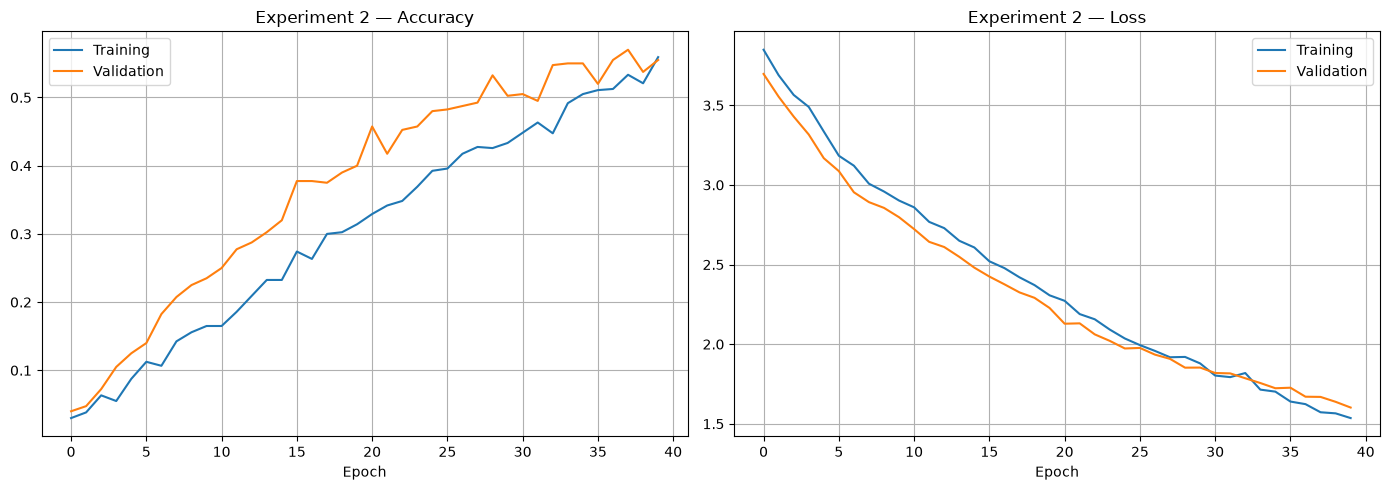

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(history_lr.history["accuracy"], label="Training")
axes[0].plot(history_lr.history["val_accuracy"], label="Validation")
axes[0].set_title("Experiment 2 — Accuracy")
axes[0].set_xlabel("Epoch")
axes[0].legend()
axes[0].grid(True)

axes[1].plot(history_lr.history["loss"], label="Training")
axes[1].plot(history_lr.history["val_loss"], label="Validation")
axes[1].set_title("Experiment 2 — Loss")
axes[1].set_xlabel("Epoch")
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.show()


In [ ]:
def spec_augment(spectrogram, freq_mask_max=12, time_mask_max=20):
    """
    spectrogram shape: (batch, mel_bins, time_frames, channels)
    """
    batch_size = tf.shape(spectrogram)[0]
    mel_bins = tf.shape(spectrogram)[1]
    time_frames = tf.shape(spectrogram)[2]

    # Frequency masking
    freq_width = tf.random.uniform(
        [], minval=0, maxval=freq_mask_max + 1, dtype=tf.int32
    )
    freq_start = tf.random.uniform(
        [], minval=0,
        maxval=tf.maximum(mel_bins - freq_width + 1, 1),
        dtype=tf.int32
    )
    freq_positions = tf.range(mel_bins)
    freq_mask = tf.logical_or(
        freq_positions < freq_start,
        freq_positions >= freq_start + freq_width
    )
    freq_mask = tf.cast(freq_mask, spectrogram.dtype)
    freq_mask = tf.reshape(freq_mask, [1, mel_bins, 1, 1])

    augmented = spectrogram * freq_mask

    # Time masking
    time_width = tf.random.uniform(
        [], minval=0, maxval=time_mask_max + 1, dtype=tf.int32
    )
    time_start = tf.random.uniform(
        [], minval=0,
        maxval=tf.maximum(time_frames - time_width + 1, 1),
        dtype=tf.int32
    )
    time_positions = tf.range(time_frames)
    time_mask = tf.logical_or(
        time_positions < time_start,
        time_positions >= time_start + time_width
    )
    time_mask = tf.cast(time_mask, spectrogram.dtype)
    time_mask = tf.reshape(time_mask, [1, 1, time_frames, 1])

    augmented = augmented * time_mask

    return augmented


In [ ]:
model_aug = keras.Sequential([
    keras.Input(shape=(128, 216, 1)),

    layers.Conv2D(32, 3, padding="same", activation="relu"),
    layers.MaxPooling2D(2),

    layers.Conv2D(64, 3, padding="same", activation="relu"),
    layers.MaxPooling2D(2),

    layers.Conv2D(128, 3, padding="same", activation="relu"),
    layers.MaxPooling2D(2),

    layers.GlobalAveragePooling2D(),
    layers.Dropout(0.3),
    layers.Dense(50, activation="softmax")
])

model_aug.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("SpecAugment CNN created.")
model_aug.summary()


SpecAugment CNN created.


Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_9 (Conv2D)               │ (None, 128, 216, 32)   │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_9 (MaxPooling2D)  │ (None, 64, 108, 32)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_10 (Conv2D)              │ (None, 64, 108, 64)    │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_10 (MaxPooling2D) │ (None, 32, 54, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_11 (Conv2D)              │ (None, 32, 54, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_11 (MaxPooling2D) │ (None, 16, 27, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_3      │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 50)             │         6,450 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 99,122 (387.20 KB)

 Trainable params: 99,122 (387.20 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:

BATCH_SIZE = 32
AUTOTUNE = tf.data.AUTOTUNE

train_ds = (
    tf.data.Dataset
    .from_tensor_slices((X_train_norm, y_train_encoded))
    .shuffle(len(X_train_norm), seed=42)
    .batch(BATCH_SIZE)
    .map(
        lambda x, y: (spec_augment(x), y),
        num_parallel_calls=AUTOTUNE
    )
    .prefetch(AUTOTUNE)
)

val_ds = ( tf.data.Dataset.from_tensor_slices((X_val_norm, y_val_encoded)).batch(BATCH_SIZE).prefetch(AUTOTUNE) )

early_stopping_aug = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=8,
    restore_best_weights=True,
    verbose=1
)

history_aug = model_aug.fit(
    train_ds,
    validation_data=val_ds,
    epochs=40,
    callbacks=[early_stopping_aug],
    verbose=1
)

best_epoch_aug = min( range(len(history_aug.history["val_loss"])), key=lambda i: history_aug.history["val_loss"][i] )

print("Epochs completed:", len(history_aug.history["accuracy"]))
print("Best validation accuracy:", max(history_aug.history["val_accuracy"]))
print("Best validation loss:", min(history_aug.history["val_loss"]))
print("Accuracy at best-loss epoch:", history_aug.history["val_accuracy"][best_epoch_aug])

Epoch 1/40


c:\Users\MinhalHnaqvi\Desktop\DL-ESC50\.venv\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


38/38 ━━━━━━━━━━━━━━━━━━━━ 12s 279ms/step - accuracy: 0.0367 - loss: 3.8583 - val_accuracy: 0.0500 - val_loss: 3.7236
Epoch 2/40
38/38 ━━━━━━━━━━━━━━━━━━━━ 10s 266ms/step - accuracy: 0.0425 - loss: 3.7186 - val_accuracy: 0.0550 - val_loss: 3.6112
Epoch 3/40
38/38 ━━━━━━━━━━━━━━━━━━━━ 10s 274ms/step - accuracy: 0.0517 - loss: 3.6403 - val_accuracy: 0.0700 - val_loss: 3.5475
Epoch 4/40
38/38 ━━━━━━━━━━━━━━━━━━━━ 11s 284ms/step - accuracy: 0.0600 - loss: 3.5673 - val_accuracy: 0.0700 - val_loss: 3.4502
Epoch 5/40
38/38 ━━━━━━━━━━━━━━━━━━━━ 10s 266ms/step - accuracy: 0.0642 - loss: 3.5010 - val_accuracy: 0.0875 - val_loss: 3.4428
Epoch 6/40
38/38 ━━━━━━━━━━━━━━━━━━━━ 10s 270ms/step - accuracy: 0.0958 - loss: 3.4043 - val_accuracy: 0.1475 - val_loss: 3.2653
Epoch 7/40
38/38 ━━━━━━━━━━━━━━━━━━━━ 10s 268ms/step - accuracy: 0.1025 - loss: 3.2978 - val_accuracy: 0.1350 - val_loss: 3.1841
Epoch 8/40
38/38 ━━━━━━━━━━━━━━━━━━━━ 10s 272ms/step - accuracy: 0.1158 - loss: 3.2453 - val_accuracy: 0.150

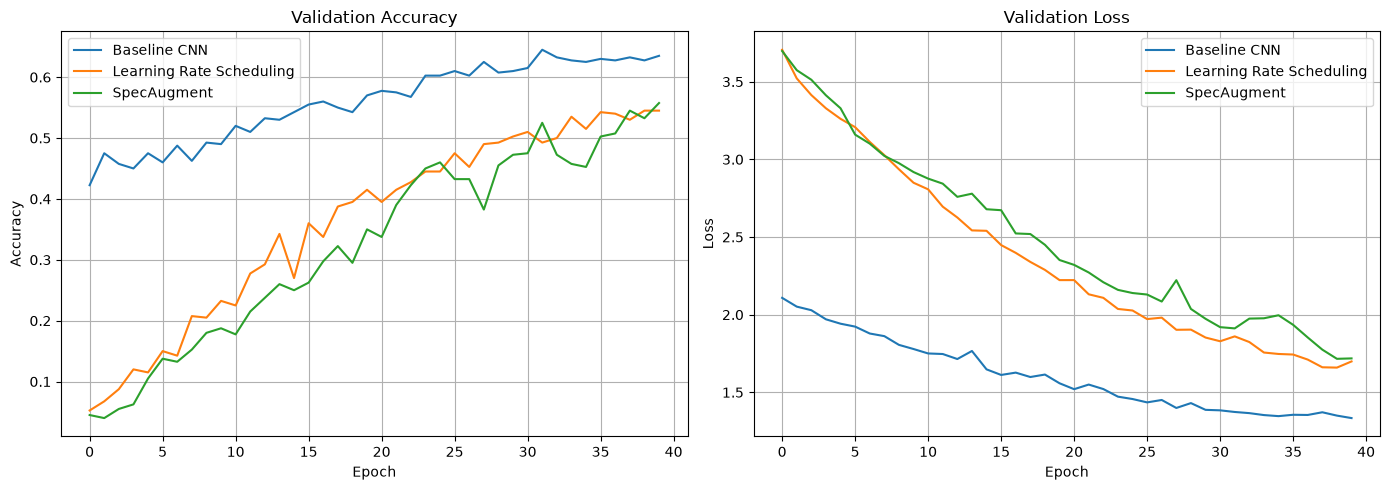

In [ ]:
histories = {
    "Baseline CNN": history_long,
    "Learning Rate Scheduling": history_lr,
    "SpecAugment": history_aug,
}

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for name, hist in histories.items():
    axes[0].plot(hist.history["val_accuracy"], label=name)
    axes[1].plot(hist.history["val_loss"], label=name)

axes[0].set_title("Validation Accuracy")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Accuracy")
axes[0].legend()
axes[0].grid(True)

axes[1].set_title("Validation Loss")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Loss")
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.show()

In [ ]:
experiments = {
    "Baseline CNN": history_long,
    "Learning Rate Scheduling": history_lr,
    "SpecAugment": history_aug,
}

results = []

for name, hist in experiments.items():
    best_loss_idx = min(
        range(len(hist.history["val_loss"])),
        key=lambda i: hist.history["val_loss"][i]
    )

    results.append({
        "Experiment": name,
        "Epochs": len(hist.history["val_loss"]),
        "Best Val Accuracy (%)": round(
            max(hist.history["val_accuracy"]) * 100, 2
        ),
        "Best Val Loss": round(
            min(hist.history["val_loss"]), 4
        ),
        "Accuracy at Best Loss (%)": round(
            hist.history["val_accuracy"][best_loss_idx] * 100, 2
        ),
    })

results_df = pd.DataFrame(results)
display(results_df)

,Experiment,Epochs,Best Val Accuracy (%),Best Val Loss,Accuracy at Best Loss (%)
0,Baseline CNN,40,64.50,1.3343,63.50
1,Learning Rate Scheduling,40,54.50,1.6593,54.50
2,SpecAugment,40,55.75,1.7158,53.25


In [ ]:
OUTPUT_DIR = Path("outputs")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Save the trained models
model.save(OUTPUT_DIR / "cnn_baseline.keras")
model_lr.save(OUTPUT_DIR / "cnn_learning_rate.keras")
model_aug.save(OUTPUT_DIR / "cnn_spec_augment.keras")

# Save training histories
histories = {
    "baseline": history_long,
    "learning_rate": history_lr,
    "spec_augment": history_aug,
}

for name, hist in histories.items():
    history_data = {
        key: [float(value) for value in values]
        for key, values in hist.history.items()
    }

    with open(OUTPUT_DIR / f"{name}_history.json", "w") as file:
        json.dump(history_data, file, indent=2)

print("Models and experiment histories saved successfully.")

for path in sorted(OUTPUT_DIR.iterdir()):
    print(path)

Models and experiment histories saved successfully.
outputs/baseline_history.json
outputs/cnn_baseline.keras
outputs/cnn_baseline_history.json
outputs/cnn_learning_rate.keras
outputs/cnn_spec_augment.keras
outputs/learning_rate_history.json
outputs/spec_augment_history.json


In [ ]:
import importlib.util

packages = ["torch", "transformers", "torchaudio", "librosa"]

for package in packages:
    installed = importlib.util.find_spec(package) is not None
    print(f"{package}: {'Installed' if installed else 'Not installed'}")

torch: Installed
transformers: Installed
torchaudio: Not installed
librosa: Installed


In [ ]:
import torch
import transformers

print("PyTorch:", torch.__version__)
print("Transformers:", transformers.__version__)
print("MPS available:", torch.backends.mps.is_available())

PyTorch: 2.2.2
Transformers: 4.56.2
MPS available: True


In [ ]:
import torch
import transformers
from transformers import ASTForAudioClassification, ASTFeatureExtractor

print("PyTorch:", torch.__version__)
print("Transformers:", transformers.__version__)
print("AST model imports: successful")

PyTorch: 2.2.2
Transformers: 4.56.2
AST model imports: successful


In [ ]:
import sys
import torch
import transformers
import importlib.metadata as metadata

print("Python executable:", sys.executable)
print("PyTorch version:", torch.__version__)
print("PyTorch location:", torch.__file__)
print("Transformers version:", transformers.__version__)
print("Transformers location:", transformers.__file__)
print("Installed package version:", metadata.version("transformers"))

Python executable: /Volumes/Coding Work Place/DL-ESC50/.venv/bin/python
PyTorch version: 2.2.2
PyTorch location: /Volumes/Coding Work Place/DL-ESC50/.venv/lib/python3.12/site-packages/torch/__init__.py
Transformers version: 4.56.2
Transformers location: /Volumes/Coding Work Place/DL-ESC50/.venv/lib/python3.12/site-packages/transformers/__init__.py
Installed package version: 4.56.2


In [ ]:
from transformers import ASTForAudioClassification

MODEL_NAME = "MIT/ast-finetuned-audioset-10-10-0.4593"

device = torch.device(
    "mps" if torch.backends.mps.is_available() else "cpu"
)

print("Device:", device)
print("Loading pretrained AST model...")

ast_model = ASTForAudioClassification.from_pretrained(
    MODEL_NAME
)

ast_model.to(device)
ast_model.eval()

print("Model loaded successfully.")
print("Pretrained classes:", ast_model.config.num_labels)

Device: mps
Loading pretrained AST model...
Model loaded successfully.
Pretrained classes: 527


In [ ]:
from transformers import ASTFeatureExtractor

MODEL_NAME = "MIT/ast-finetuned-audioset-10-10-0.4593"

feature_extractor = ASTFeatureExtractor.from_pretrained(MODEL_NAME)

print("Sampling rate:", feature_extractor.sampling_rate)
print("Feature extractor loaded successfully.")

Sampling rate: 16000
Feature extractor loaded successfully.


/Volumes/Coding Work Place/DL-ESC50/.venv/lib/python3.12/site-packages/transformers/audio_utils.py:525: UserWarning: At least one mel filter has all zero values. The value for `num_mel_filters` (128) may be set too high. Or, the value for `num_frequency_bins` (257) may be set too low.
  warnings.warn(


In [ ]:
waveform, sr = librosa.load(
    audio_path,
    sr=feature_extractor.sampling_rate,
    mono=True
)

print("File:", sample_file.name)
print("Waveform shape:", waveform.shape)
print("Sampling rate:", sr)
print("Duration (seconds):", round(len(waveform) / sr, 2))

File: 1-100032-A-0.wav
Waveform shape: (80000,)
Sampling rate: 16000
Duration (seconds): 5.0


In [ ]:
sample_inputs = feature_extractor(
    waveform,
    sampling_rate=sr,
    return_tensors="pt"
)

print("Input keys:", sample_inputs.keys())
print("Input shape:", sample_inputs["input_values"].shape)

Input keys: KeysView({'input_values': tensor([[[-1.1001, -1.2776, -1.0276,  ..., -0.5243, -0.6456, -1.0080],
         [-1.1302, -1.2776, -1.1576,  ..., -0.4888, -0.6592, -1.0460],
         [-1.2776, -1.2776, -1.2385,  ..., -0.4928, -0.6133, -0.9418],
         ...,
         [ 0.4670,  0.4670,  0.4670,  ...,  0.4670,  0.4670,  0.4670],
         [ 0.4670,  0.4670,  0.4670,  ...,  0.4670,  0.4670,  0.4670],
         [ 0.4670,  0.4670,  0.4670,  ...,  0.4670,  0.4670,  0.4670]]])})
Input shape: torch.Size([1, 1024, 128])


In [ ]:
import gc
from sklearn.preprocessing import LabelEncoder

# Use CPU to reduce pressure on your Mac's shared GPU/system memory.
device = torch.device("cpu")
ast_model.to(device)
ast_model.eval()

# Official ESC-50 folds: train = 1–3, validation = 4.
metadata = pd.read_csv(DATASET_DIR / "meta" / "esc50.csv")

train_rows = metadata[metadata["fold"].isin([1, 2, 3])]
val_rows = metadata[metadata["fold"] == 4]

# Create consistent class IDs for all 50 classes.
ast_label_encoder = LabelEncoder()
ast_label_encoder.fit(train_rows["category"])

# Small, class-balanced pilot: 2 train clips and 1 validation clip per class.
train_small = (
    train_rows.groupby("category", group_keys=False)
    .sample(n=2, random_state=42)
    .reset_index(drop=True)
)

val_small = (
    val_rows.groupby("category", group_keys=False)
    .sample(n=1, random_state=42)
    .reset_index(drop=True)
)

# Save each embedding separately so completed work can be reused.
CACHE_DIR = Path("outputs/ast_pilot_cache")
CACHE_DIR.mkdir(parents=True, exist_ok=True)

def extract_one_embedding(filename):
    cache_file = CACHE_DIR / f"{Path(filename).stem}.npy"

    if cache_file.exists():
        return np.load(cache_file)

    audio, _ = librosa.load(
        AUDIO_DIR / filename,
        sr=feature_extractor.sampling_rate,
        mono=True
    )

    inputs = feature_extractor(
        audio,
        sampling_rate=feature_extractor.sampling_rate,
        return_tensors="pt"
    )

    with torch.inference_mode():
        output = ast_model.audio_spectrogram_transformer(
            input_values=inputs["input_values"].to(device),
            return_dict=True
        )
        embedding = output.last_hidden_state[0, 0, :].cpu().numpy()

    np.save(cache_file, embedding)

    del audio, inputs, output
    return embedding

def extract_dataset(rows, name):
    features = []
    labels = []

    for row in tqdm(
        rows.itertuples(index=False),
        total=len(rows),
        desc=name
    ):
        features.append(extract_one_embedding(row.filename))
        labels.append(ast_label_encoder.transform([row.category])[0])

        # Release temporary objects between clips.
        gc.collect()

    return np.asarray(features, dtype=np.float32), np.asarray(labels)

X_ast_train_small, y_ast_train_small = extract_dataset(
    train_small, "Small training set"
)

X_ast_val_small, y_ast_val_small = extract_dataset(
    val_small, "Small validation set"
)

print("Training features:", X_ast_train_small.shape)
print("Validation features:", X_ast_val_small.shape)
print("Training labels:", y_ast_train_small.shape)
print("Validation labels:", y_ast_val_small.shape)

Small validation set: 100%|██████████| 50/50 [01:18<00:00,  1.57s/it]

Training features: (100, 768)
Validation features: (50, 768)
Training labels: (100,)
Validation labels: (50,)


In [ ]:
import torch
import torch.nn as nn
from transformers import ASTForAudioClassification

MODEL_NAME = "MIT/ast-finetuned-audioset-10-10-0.4593"

num_classes = len(ast_label_encoder.classes_)

ast_classifier_model = ASTForAudioClassification.from_pretrained(
    MODEL_NAME,
    num_labels=num_classes,
    ignore_mismatched_sizes=True,
    id2label={
        i: label for i, label in enumerate(ast_label_encoder.classes_)
    },
    label2id={
        label: i for i, label in enumerate(ast_label_encoder.classes_)
    }
)

print("Output classes:", ast_classifier_model.config.num_labels)
print("Backbone:", type(ast_classifier_model.audio_spectrogram_transformer).__name__)
print("Classification head:", ast_classifier_model.classifier)

Some weights of ASTForAudioClassification were not initialized from the model checkpoint at MIT/ast-finetuned-audioset-10-10-0.4593 and are newly initialized because the shapes did not match:
- classifier.dense.bias: found shape torch.Size([527]) in the checkpoint and torch.Size([50]) in the model instantiated
- classifier.dense.weight: found shape torch.Size([527, 768]) in the checkpoint and torch.Size([50, 768]) in the model instantiated
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


Output classes: 50
Backbone: ASTModel
Classification head: ASTMLPHead(
  (layernorm): LayerNorm((768,), eps=1e-12, elementwise_affine=True)
  (dense): Linear(in_features=768, out_features=50, bias=True)
)


In [ ]:
for param in ast_classifier_model.audio_spectrogram_transformer.parameters():
    param.requires_grad = False

trainable_params = sum(
    p.numel()
    for p in ast_classifier_model.parameters()
    if p.requires_grad
)

total_params = sum(
    p.numel() for p in ast_classifier_model.parameters()
)

print(f"Trainable parameters: {trainable_params:,}")
print(f"Total parameters: {total_params:,}")
print(
    "Backbone frozen:",
    not any(
        p.requires_grad
        for p in ast_classifier_model.audio_spectrogram_transformer.parameters()
    )
)

Trainable parameters: 39,986
Total parameters: 86,227,250
Backbone frozen: True


In [ ]:
from torch.utils.data import Dataset, DataLoader
from pathlib import Path
import pandas as pd
import numpy as np
import librosa

metadata = pd.read_csv(DATASET_DIR / "meta" / "esc50.csv")

train_rows = metadata[metadata["fold"].isin([1, 2, 3])]
val_rows = metadata[metadata["fold"] == 4]

# Small pilot: 2 training clips and 1 validation clip per class.
train_small = (
    train_rows.groupby("category", group_keys=False)
    .sample(n=2, random_state=42)
    .reset_index(drop=True)
)

val_small = (
    val_rows.groupby("category", group_keys=False)
    .sample(n=1, random_state=42)
    .reset_index(drop=True)
)

class ESC50Dataset(Dataset):
    def __init__(self, rows, label_encoder):
        self.rows = rows.reset_index(drop=True)
        self.label_encoder = label_encoder

    def __len__(self):
        return len(self.rows)

    def __getitem__(self, index):
        row = self.rows.iloc[index]

        audio, _ = librosa.load(
            AUDIO_DIR / row["filename"],
            sr=feature_extractor.sampling_rate,
            mono=True
        )

        label = self.label_encoder.transform([row["category"]])[0]
        return audio, int(label)

def ast_collate_fn(batch):
    waveforms, labels = zip(*batch)

    inputs = feature_extractor(
        list(waveforms),
        sampling_rate=feature_extractor.sampling_rate,
        return_tensors="pt"
    )

    return inputs["input_values"], torch.tensor(labels, dtype=torch.long)

train_loader = DataLoader(
    ESC50Dataset(train_small, ast_label_encoder),
    batch_size=2,
    shuffle=True,
    num_workers=0,
    collate_fn=ast_collate_fn
)

val_loader = DataLoader(
    ESC50Dataset(val_small, ast_label_encoder),
    batch_size=2,
    shuffle=False,
    num_workers=0,
    collate_fn=ast_collate_fn
)

print("Training clips:", len(train_small))
print("Validation clips:", len(val_small))

Training clips: 100
Validation clips: 50


In [ ]:
import time
import torch

device = torch.device(
    "mps" if torch.backends.mps.is_available() else "cpu"
)

ast_classifier_model.to(device)

optimizer = torch.optim.AdamW(
    [p for p in ast_classifier_model.parameters() if p.requires_grad],
    lr=1e-4
)

criterion = torch.nn.CrossEntropyLoss()

start_time = time.time()
ast_classifier_model.train()

total_loss = 0.0
correct = 0
total = 0

for step, (inputs, labels) in enumerate(train_loader, start=1):
    inputs = inputs.to(device)
    labels = labels.to(device)

    optimizer.zero_grad(set_to_none=True)

    outputs = ast_classifier_model(
        input_values=inputs,
        labels=labels
    )

    outputs.loss.backward()
    optimizer.step()

    total_loss += outputs.loss.item() * labels.size(0)
    predictions = outputs.logits.argmax(dim=1)
    correct += (predictions == labels).sum().item()
    total += labels.size(0)

    if step % 10 == 0:
        print(f"Batch {step}/{len(train_loader)} completed")

print(f"Training loss: {total_loss / total:.4f}")
print(f"Training accuracy: {correct / total:.2%}")
print(f"Training time: {(time.time() - start_time) / 60:.2f} minutes")

Batch 10/50 completed
Batch 20/50 completed
Batch 30/50 completed
Batch 40/50 completed
Batch 50/50 completed
Training loss: 4.1505
Training accuracy: 1.00%
Training time: 5.67 minutes


In [ ]:
from sklearn.metrics import accuracy_score, f1_score
import numpy as np
import time

ast_classifier_model.eval()

val_true = []
val_pred = []

start_time = time.time()

with torch.inference_mode():
    for inputs, labels in val_loader:
        inputs = inputs.to(device)

        outputs = ast_classifier_model(input_values=inputs)
        predictions = outputs.logits.argmax(dim=1).cpu().numpy()

        val_pred.extend(predictions.tolist())
        val_true.extend(labels.numpy().tolist())

print(f"Validation accuracy: {accuracy_score(val_true, val_pred):.2%}")
print(f"Validation macro-F1: {f1_score(val_true, val_pred, average='macro', zero_division=0):.4f}")
print(f"Validation time: {(time.time() - start_time) / 60:.2f} minutes")

Validation accuracy: 2.00%
Validation macro-F1: 0.0031
Validation time: 2.83 minutes


In [ ]:
import time
import torch
import numpy as np
from sklearn.metrics import accuracy_score, f1_score

# Ensure only the classification head is trainable.
for param in ast_classifier_model.audio_spectrogram_transformer.parameters():
    param.requires_grad = False

optimizer = torch.optim.AdamW(
    [p for p in ast_classifier_model.parameters() if p.requires_grad],
    lr=1e-3
)

device = next(ast_classifier_model.parameters()).device
history_ast = {"train_loss": [], "train_accuracy": [],
               "val_accuracy": [], "val_macro_f1": []}

for epoch in range(5):
    start_time = time.time()
    ast_classifier_model.train()

    train_loss_sum = 0.0
    train_correct = 0
    train_total = 0

    for inputs, labels in train_loader:
        inputs = inputs.to(device)
        labels = labels.to(device)

        optimizer.zero_grad(set_to_none=True)
        outputs = ast_classifier_model(input_values=inputs, labels=labels)
        outputs.loss.backward()
        optimizer.step()

        train_loss_sum += outputs.loss.item() * labels.size(0)
        train_correct += (
            outputs.logits.argmax(dim=1) == labels
        ).sum().item()
        train_total += labels.size(0)

    ast_classifier_model.eval()
    val_true, val_pred = [], []

    with torch.inference_mode():
        for inputs, labels in val_loader:
            outputs = ast_classifier_model(input_values=inputs.to(device))
            val_pred.extend(outputs.logits.argmax(dim=1).cpu().tolist())
            val_true.extend(labels.tolist())

    train_loss = train_loss_sum / train_total
    train_acc = train_correct / train_total
    val_acc = accuracy_score(val_true, val_pred)
    val_f1 = f1_score(
        val_true, val_pred, average="macro", zero_division=0
    )

    history_ast["train_loss"].append(train_loss)
    history_ast["train_accuracy"].append(train_acc)
    history_ast["val_accuracy"].append(val_acc)
    history_ast["val_macro_f1"].append(val_f1)

    print(
        f"Epoch {epoch + 1}/5 | "
        f"loss={train_loss:.4f} | "
        f"train_acc={train_acc:.2%} | "
        f"val_acc={val_acc:.2%} | "
        f"macro_F1={val_f1:.4f} | "
        f"time={(time.time() - start_time) / 60:.1f} min"
    )

In [ ]:
import torch
from transformers import ASTForAudioClassification, ASTFeatureExtractor

MODEL_NAME = "MIT/ast-finetuned-audioset-10-10-0.4593"

feature_extractor = ASTFeatureExtractor.from_pretrained(MODEL_NAME)

ast_classifier_model = ASTForAudioClassification.from_pretrained(
    MODEL_NAME,
    num_labels=50,
    ignore_mismatched_sizes=True
)

print("Pretrained AST model loaded.")
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    ast_classifier_model = ast_classifier_model.to("cuda")
else:
    print("GPU not detected. Model is currently on CPU.")

Xet Storage is enabled for this repo, but the 'hf_xet' package is not installed. Falling back to regular HTTP download. For better performance, install the package with: `pip install huggingface_hub[hf_xet]` or `pip install hf_xet`
Some weights of ASTForAudioClassification were not initialized from the model checkpoint at MIT/ast-finetuned-audioset-10-10-0.4593 and are newly initialized because the shapes did not match:
- classifier.dense.bias: found shape torch.Size([527]) in the checkpoint and torch.Size([50]) in the model instantiated
- classifier.dense.weight: found shape torch.Size([527, 768]) in the checkpoint and torch.Size([50, 768]) in the model instantiated
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


Pretrained AST model loaded.
CUDA available: False
GPU not detected. Model is currently on CPU.


In [ ]:
import torch
import subprocess

print("PyTorch version:", torch.__version__)
print("CUDA build:", torch.version.cuda)
print("CUDA available:", torch.cuda.is_available())

try:
    result = subprocess.run(
        ["nvidia-smi"],
        capture_output=True,
        text=True,
        timeout=10
    )
    print("\nnvidia-smi output:")
    print(result.stdout if result.returncode == 0 else result.stderr)
except Exception as e:
    print("Could not run nvidia-smi:", e)

PyTorch version: 2.2.2+cpu
CUDA build: None
CUDA available: False

nvidia-smi output:
Mon Oct 26 00:07:18 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 616.92                 KMD Version: 616.92        CUDA UMD Version: 13.4     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                  Driver-Model | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  NVIDIA GeForce RTX 3060      WDDM  |   00000000:03:00.0  On |                  N/A |
|  0%   50C    P8             22W /  170W |    1401MiB /  12288MiB |     31%      Default |
|                                         |           

In [ ]:
import torch

print("PyTorch version:", torch.__version__)
print("CUDA version:", torch.version.cuda)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU name:", torch.cuda.get_device_name(0))
    print("GPU ready for training!")
else:
    print("GPU not connected to PyTorch yet.")


A module that was compiled using NumPy 1.x cannot be run in
NumPy 2.5.2 as it may crash. To support both 1.x and 2.x
versions of NumPy, modules must be compiled with NumPy 2.0.
Some module may need to rebuild instead e.g. with 'pybind11>=2.12'.

If you are a user of the module, the easiest solution will be to
downgrade to 'numpy<2' or try to upgrade the affected module.
We expect that some modules will need time to support NumPy 2.

Traceback (most recent call last):  File "<frozen runpy>", line 198, in _run_module_as_main
  File "<frozen runpy>", line 88, in _run_code
  File "c:\Users\MinhalHnaqvi\Desktop\DL-ESC50\.venv\Lib\site-packages\ipykernel_launcher.py", line 18, in <module>
    app.launch_new_instance()
  File "c:\Users\MinhalHnaqvi\Desktop\DL-ESC50\.venv\Lib\site-packages\traitlets\config\application.py", line 1080, in launch_instance
    app.start()
  File "c:\Users\MinhalHnaqvi\Desktop\DL-ESC50\.venv\Lib\site-packages\ipykernel\kernelapp.py", line 768, in start
    self.io

PyTorch version: 2.2.2+cu121
CUDA version: 12.1
CUDA available: True
GPU name: NVIDIA GeForce RTX 3060
GPU ready for training!


In [ ]:
import torch

device = torch.device("cuda")

# Move the existing pretrained AST model onto the GPU.
ast_classifier_model = ast_classifier_model.to(device)

# Unfreeze the entire pretrained model.
for param in ast_classifier_model.parameters():
    param.requires_grad = True

print("Device:", next(ast_classifier_model.parameters()).device)
print("GPU:", torch.cuda.get_device_name(0))
print("Training clips:", len(train_loader.dataset))
print("Validation clips:", len(val_loader.dataset))
print(
    "Trainable parameters:",
    sum(p.numel() for p in ast_classifier_model.parameters() if p.requires_grad)
)

NameError: name 'ast_classifier_model' is not defined